# fedOPD - exploratory analysis

The first pass over the finished canonical table. Everything here reads `data/canonical/`; nothing is
re-derived from the raw CSVs and nothing is written back.

Three questions, each of which was previously answered in an ad-hoc shell command and therefore could
not be reproduced:

1. What has the 18-week standard actually done across the window?
2. Does independent-sector share respond to public backlog, and at what lag?
3. What does the backlog identity do to a single real trust over a real stretch of months?

In [1]:
import pandas as pd                            # all tabular work
import matplotlib.pyplot as plt                 # the plots
from pathlib import Path                        # filesystem paths

CANON = Path("../data/canonical")               # everything data_processing.ipynb produced
canon = pd.read_parquet(CANON / "rtt_canonical.parquet")   # 653 providers, all sectors
panel = pd.read_parquet(CANON / "rtt_panel.parquet")       # the 126-trust federation cube

print(f"canonical {canon.shape[0]:,} x {canon.shape[1]}   panel {panel.shape[0]:,} x {panel.shape[1]}")
print(f"months {canon.month.min():%Y-%m} to {canon.month.max():%Y-%m}")

canonical 322,531 x 15   panel 229,824 x 20
months 2018-04 to 2026-03


## 1. The 18-week standard across the window

The operational standard is that 92% of people **still waiting** have waited under 18 weeks. So the
measure is `(waiting - waiting_gt18) / waiting`, on the all-provider basis, which is what NHS
publishes against.

Watch the two series separately. The size of the queue and the age of the queue are different
quantities, and conflating them is the easiest mistake to make here.

In [2]:
# national monthly totals, all providers, then the standard as a percentage
nat = canon.groupby("month")[["waiting", "waiting_gt18", "demand", "completed"]].sum()
nat["within18_pct"] = (nat.waiting - nat.waiting_gt18) / nat.waiting * 100   # the published measure

# the months worth quoting: the ends, the two extremes, and the pre-COVID reference
marks = ["2018-04-01", "2020-02-01", "2020-07-01", "2022-03-01",
         "2023-08-01", "2024-03-01", "2026-03-01"]
print(f"{'month':10s} {'waiting':>12s} {'within 18 weeks':>16s}")
for m in marks:
    r = nat.loc[m]
    print(f"{m[:7]:10s} {r.waiting/1e6:>11.2f}m {r.within18_pct:>15.1f}%")

print()
print(f"performance trough : {nat.within18_pct.idxmin():%Y-%m}  {nat.within18_pct.min():.1f}%")
print(f"performance peak   : {nat.within18_pct.idxmax():%Y-%m}  {nat.within18_pct.max():.1f}%")
print(f"waiting list peak  : {nat.waiting.idxmax():%Y-%m}  {nat.waiting.max()/1e6:.2f}m")
print()
# the point of the whole section: the two extremes are years apart, so they are not one phenomenon
gap = abs((nat.waiting.idxmax() - nat.within18_pct.idxmin()).days) / 365.25
print(f"list peak and performance trough are {gap:.1f} years apart - they are not the same event")

month           waiting  within 18 weeks
2018-04           4.04m            87.5%
2020-02           4.44m            83.1%
2020-07           4.07m            46.8%
2022-03           6.39m            62.1%
2023-08           7.78m            58.0%
2024-03           7.57m            57.2%
2026-03           7.05m            65.2%

performance trough : 2020-07  46.8%
performance peak   : 2018-05  88.1%
waiting list peak  : 2023-08  7.78m

list peak and performance trough are 3.1 years apart - they are not the same event


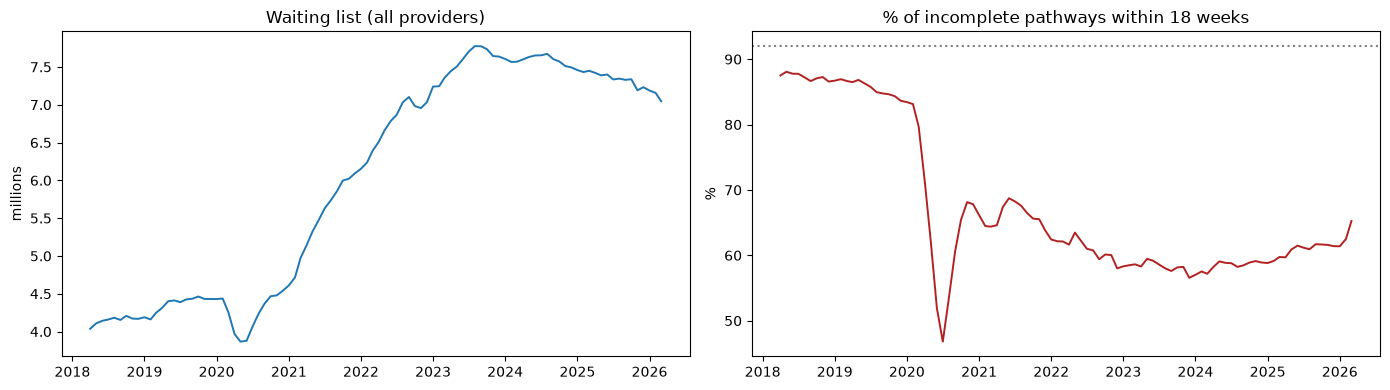

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(nat.index, nat.waiting / 1e6, lw=1.4)
ax[0].set_title("Waiting list (all providers)"); ax[0].set_ylabel("millions")
ax[1].plot(nat.index, nat.within18_pct, lw=1.4, color="firebrick")
ax[1].axhline(92, color="grey", ls=":")          # the operational standard, for scale
ax[1].set_title("% of incomplete pathways within 18 weeks"); ax[1].set_ylabel("%")
plt.tight_layout()

## 2. Does independent share respond to public backlog?

The intuitive mechanism is that public backlog rises, so commissioners buy capacity from independent
providers. If that happens at a monthly cadence, the **change** in independent share should follow the
**change** in public backlog with some lag.

Differencing both series removes the level and the long-run trend, which is what isolates a response
rather than a shared drift. Note in advance what a positive result at lag 0 would and would not mean:
commissioners buy independent capacity *because* waits are long, so the two are jointly determined and
a same-month association is expected without any substitution having occurred.

In [4]:
# per specialty per month: public backlog, and the independent share of that month's demand
g = (canon.groupby(["dept", "month", "sector"])[["demand", "waiting"]].sum()
          .unstack("sector").fillna(0))
g.columns = ["_".join(c) for c in g.columns]                       # flatten the MultiIndex
g["ind_share"] = g.demand_independent / (g.demand_independent + g.demand_public) * 100
g = g.reset_index()

LAGS = (0, 3, 6, 12)                                               # months to test
rows = []
for dept, s in g[g.dept != "X_OTHER"].groupby("dept"):             # the 18 named specialties only
    s = s.sort_values("month")
    d_share = s.ind_share.diff()                                   # month-on-month change in share
    d_back = s.waiting_public.pct_change()                         # month-on-month change in backlog
    # .shift(k) moves the backlog series DOWN k rows, so row t is compared with backlog at t-k
    rows.append({"dept": dept, **{f"lag{k}": d_share.corr(d_back.shift(k)) for k in LAGS}})

corr = pd.DataFrame(rows).set_index("dept")
print(corr.round(3).to_string())
print()
print("mean across the 18 named specialties:")
print(corr.mean().round(3).to_string())
print()
for k in LAGS:
    pos = int((corr[f"lag{k}"] > 0).sum())
    print(f"  lag {k:>2}: {pos} of {len(corr)} specialties positive")

        lag0   lag3   lag6  lag12
dept                             
C_100  0.250  0.010  0.096  0.102
C_101  0.035 -0.063 -0.052  0.040
C_110  0.126 -0.019  0.086  0.047
C_120  0.206 -0.036  0.017 -0.072
C_130  0.314 -0.062  0.028  0.005
C_140 -0.018 -0.060 -0.026  0.099
C_150  0.175 -0.074 -0.095  0.118
C_160 -0.078  0.004  0.215 -0.018
C_170  0.025 -0.040 -0.327  0.008
C_300 -0.302  0.271  0.147  0.030
C_301  0.287 -0.027 -0.018 -0.017
C_320  0.017 -0.036  0.003  0.102
C_330 -0.128 -0.004 -0.024 -0.064
C_340  0.043 -0.163 -0.114  0.100
C_400 -0.028 -0.039 -0.003 -0.100
C_410  0.095  0.058 -0.092 -0.006
C_430  0.111  0.035 -0.147 -0.131
C_502  0.267 -0.024 -0.013 -0.103

mean across the 18 named specialties:
lag0     0.078
lag3    -0.015
lag6    -0.018
lag12    0.008

  lag  0: 13 of 18 specialties positive
  lag  3: 5 of 18 specialties positive
  lag  6: 7 of 18 specialties positive
  lag 12: 10 of 18 specialties positive


**Reading it.** A mean correlation near zero at every lag, with roughly half the specialties positive
at each, is what you get from no relationship. The only non-trivial figure is at lag 0, and a
same-month association is exactly what joint determination produces.

What this rules out is a **fast** response. It does not rule out a slow one, and the long-run trend
says a slow one exists: independent share of ophthalmology moves from about 6% to about 20% across the
window. Substitution here is a multi-year contracting shift, not a monthly release valve.

In [5]:
# the slow shift, for contrast with the null result above
share = (canon.groupby(["dept", "month", "sector"]).demand.sum().unstack("sector").fillna(0))
share["pct"] = share.independent / (share.independent + share.public) * 100
first_last = (share.reset_index().groupby("dept").pct.agg(["first", "last"]))
first_last["change_pp"] = first_last["last"] - first_last["first"]
print("independent share of demand, first month vs last, biggest movers:")
print(first_last.reindex(first_last.change_pp.abs().sort_values(ascending=False).index)
                .head(8).round(2).to_string())

independent share of demand, first month vs last, biggest movers:
       first   last  change_pp
dept                          
C_130   6.20  19.65      13.45
C_150   4.84   9.33       4.49
C_330   6.81  11.11       4.30
C_100   6.60  10.39       3.79
C_301  11.34   8.25      -3.09
C_502   5.74   3.47      -2.27
C_170   1.52   0.00      -1.52
C_140   2.87   4.38       1.51


## 3. What the identity does to one real trust

Pick a real client and a real department and apply the stated backlog identity over a stretch of
months, then compare it with what the waiting list actually did. This is the concrete version of the
unreported-removals finding.

In [6]:
TRUST, DEPT, N = "RTD", "C_110", 8            # a panel trust, Trauma & Orthopaedics, last 8 months

s = panel[(panel.provider_code == TRUST) & (panel.dept == DEPT)].sort_values("month")
window = s.tail(N + 1)                        # N months of change needs N+1 observations
opening = window.iloc[0]                      # the month the projection starts from
steps = window.iloc[1:]                       # the N months being projected over

steps_gap = steps.demand - steps.completed    # arrivals minus throughput, per month
projected = opening.waiting + steps_gap.sum() # the identity, applied over the whole window
actual = steps.iloc[-1].waiting               # what the waiting list really did

print(f"{TRUST} {DEPT}, {steps.iloc[0].month:%Y-%m} to {steps.iloc[-1].month:%Y-%m}")
print(window[["month", "demand", "completed", "waiting"]].to_string(index=False))
print()
print(f"opening backlog ({opening.month:%Y-%m})   : {opening.waiting:>10,.0f}")
print(f"sum of {N} monthly gaps            : {steps_gap.sum():>10,.0f}  (mean {steps_gap.mean():,.0f}/month)")
print(f"months with demand > throughput   : {int((steps_gap > 0).sum())} of {N}")
print(f"identity projection               : {projected:>10,.0f}")
print(f"actual backlog                    : {actual:>10,.0f}")
print(f"over-prediction                   : {(projected - actual) / actual * 100:>9.0f}%")
print()
print("The identity says this department is in crisis. The waiting list says it is flat.")
print("The difference is unreported removals, and it compounds with the projection horizon.")

RTD C_110, 2025-08 to 2026-03
     month  demand  completed  waiting
2025-07-01    4950       4040     7922
2025-08-01    3673       2811     7847
2025-09-01    4636       3827     7852
2025-10-01    4721       3784     7897
2025-11-01    4389       3504     8007
2025-12-01    3645       3001     7929
2026-01-01    4255       3555     7838
2026-02-01    3987       3479     7424
2026-03-01    4742       4013     7437

opening backlog (2025-07)   :      7,922
sum of 8 monthly gaps            :      6,074  (mean 759/month)
months with demand > throughput   : 8 of 8
identity projection               :     13,996
actual backlog                    :      7,437
over-prediction                   :        88%

The identity says this department is in crisis. The waiting list says it is flat.
The difference is unreported removals, and it compounds with the projection horizon.
